# Radar de Retenção — análise exploratória e modelagem

**Enterprise Challenge Ri Happy × FIAP** (turma 2TSCOR, Tecnologia em Data Science)
Gabriel Alves Leon Rodriguez (RM566648) — trabalho individual.

## 1. Contexto do desafio

A Ri Happy pediu uma solução para **prever o risco de desligamento voluntário de colaboradores
operacionais de loja nos primeiros 90 e 180 dias**, explicar os fatores associados e apoiar a área
de Gente & Gestão em ações preventivas de retenção.

Este notebook percorre, de forma reprodutível, o mesmo caminho do pipeline (`pipeline/01` a `03`):

1. carga e qualidade da base (sintética e pseudonimizada);
2. análise exploratória: onde e quando as saídas precoces acontecem;
3. construção das variáveis do checkpoint de 30 dias e dos alvos (90/180 dias);
4. treino e comparação de quatro modelos com divisão temporal + validação cruzada;
5. explicabilidade (SHAP), calibração e auditoria de viés;
6. conclusões, recomendações e limitações.

> Os dados são **sintéticos**: gerados por `pipeline/01_gerar_dados_sinteticos.py` com um mecanismo
> plausível de desligamento (riscos competitivos, sazonalidade e heterogeneidade não observada).
> Nenhum dado real da Ri Happy é usado.

In [1]:
import importlib.util, json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# raiz do repositório (o notebook roda a partir de notebooks/ ou da raiz)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline" / "rr_comum.py").exists())
sys.path.insert(0, str(RAIZ / "pipeline"))
import rr_comum as rc

def carregar_modulo(nome):
    spec = importlib.util.spec_from_file_location(nome, RAIZ / "pipeline" / f"{nome}.py")
    modulo = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(modulo)
    return modulo

t = carregar_modulo("02_preparar_e_treinar")   # funções de preparação, treino e explicabilidade
t.registrar = lambda msg: print(msg)
%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": rc.COR_GRADE, "axes.titlelocation": "left"})
CORES = rc.CORES_SERIE
pd.set_option("display.max_columns", 40, "display.width", 160)
print("Raiz do repositório:", RAIZ.name)

Raiz do repositório: radar-retencao


## 2. Carga dos dados

Duas tabelas, com as mesmas colunas do banco (`rr_lojas` e `rr_colaboradores`).

In [2]:
lojas, colab = t.carregar_base()
print(f"Lojas: {lojas.shape} | Colaboradores: {colab.shape}")
display(lojas.head())
display(colab.head())

Lojas: (80, 9) | Colaboradores: (7259, 28)


,loja_id,bandeira,tipo_loja,regiao,uf,cidade,porte,headcount_alvo,turnover_vol_12m
0,L001,PBKids,Shopping,Sudeste,RJ,Rio de Janeiro,Grande,48,0.5072
1,L002,Ri Happy,Shopping,Nordeste,SE,Aracaju,Pequena,17,0.2698
2,L003,Ri Happy,Shopping,Sul,PR,Curitiba,Pequena,16,0.7168
3,L004,PBKids,Shopping,Sudeste,SP,Sao Paulo,Media,33,0.2302
4,L005,Ri Happy,Rua,Nordeste,BA,Feira de Santana,Grande,56,0.1246


,colaborador_id,loja_id,cargo,tipo_contrato,faixa_etaria,faixa_salarial,escolaridade,turno,carga_horaria_semanal,canal_contratacao,experiencia_previa_varejo,distancia_casa_trabalho_km,admitido_periodo_pico,mes_admissao,data_admissao,data_desligamento,tipo_desligamento,motivo_desligamento,onboarding_concluido,horas_treinamento_30d,avaliacao_experiencia_30d,faltas_30d,atrasos_30d,horas_extras_media_semana,gestor_tempo_cargo_meses,turnover_loja_12m,dias_de_casa,status
0,C000001,L027,Vendedor,CLT Efetivo,25-34,1.5 a 2 SM,Superior Incompleto,Tarde,44,Programa Jovem,False,9.6,False,1,2023-01-01,2023-03-11,Voluntario,Outros,False,11.9,3.2,0,1,1.1,22,0.3969,69,Desligado
1,C000002,L031,Operador de Caixa,CLT Efetivo,18-24,Ate 1.5 SM,Medio,Noite,44,Site/Portal,False,27.2,False,1,2023-01-01,2023-10-15,Voluntario,Nova oportunidade,False,9.2,4.2,2,6,3.0,7,0.2690,287,Desligado
2,C000003,L043,Lider de Loja,CLT Efetivo,45-54,3 a 5 SM,Superior Completo,Tarde,36,Indicacao,True,19.6,False,1,2023-01-01,NaT,None,None,True,27.8,NaN,0,0,0.8,19,0.4423,1399,Ativo
3,C000004,L053,Operador de Caixa,CLT Efetivo,25-34,Ate 1.5 SM,Medio,Manha,44,Agencia,False,13.8,False,1,2023-01-01,2023-01-07,Voluntario,Horario/escala,None,NaN,NaN,<NA>,<NA>,NaN,4,0.4363,6,Desligado
4,C000005,L025,Vendedor,CLT Efetivo,35-44,1.5 a 2 SM,Superior Completo,Tarde,44,Indicacao,True,14.9,False,1,2023-01-02,2023-08-13,Voluntario,Nova oportunidade,False,8.3,2.9,1,1,2.7,50,0.3522,223,Desligado


## 3. Qualidade dos dados

* **Nulos**: os sinais dos primeiros 30 dias (integração, treinamento, avaliação, faltas, atrasos, horas extras)
  só existem para quem atingiu o dia 30 — para os demais são nulos por construção (checkpoint não atingido).
  A avaliação de experiência ainda tem ~10% de ausência entre os avaliáveis (não realizada), tratada por
  imputação pela média + indicador de ausência.
* **Faixas**: verificamos os domínios numéricos (distância 0-60 km, avaliação 1-5, horas 0-40 etc.).
* **Duplicidades e consistência**: identificador único, datas coerentes, status coerente com o desligamento.

In [3]:
nulos = colab.isna().mean().sort_values(ascending=False)
display(nulos[nulos > 0].rename("proporcao_nulos").to_frame().T.round(3))
sem_checkpoint = colab["dias_de_casa"] < 30
print(f"Sem checkpoint (dias_de_casa < 30): {sem_checkpoint.sum()} ({sem_checkpoint.mean():.1%}) — explica os nulos dos sinais de 30 dias")
print(f"Avaliação ausente entre quem passou do dia 30: {colab.loc[~sem_checkpoint, 'avaliacao_experiencia_30d'].isna().mean():.1%}")
display(colab[["distancia_casa_trabalho_km", "horas_treinamento_30d", "avaliacao_experiencia_30d", "faltas_30d", "atrasos_30d",
               "horas_extras_media_semana", "gestor_tempo_cargo_meses", "turnover_loja_12m", "dias_de_casa"]].astype(float).describe().round(2))

,tipo_desligamento,motivo_desligamento,data_desligamento,avaliacao_experiencia_30d,onboarding_concluido,faltas_30d,atrasos_30d,horas_treinamento_30d,horas_extras_media_semana
proporcao_nulos,0.434,0.434,0.434,0.21,0.127,0.127,0.127,0.127,0.127


Sem checkpoint (dias_de_casa < 30): 922 (12.7%) — explica os nulos dos sinais de 30 dias
Avaliação ausente entre quem passou do dia 30: 9.5%


,distancia_casa_trabalho_km,horas_treinamento_30d,avaliacao_experiencia_30d,faltas_30d,atrasos_30d,horas_extras_media_semana,gestor_tempo_cargo_meses,turnover_loja_12m,dias_de_casa
count,7259.00,6337.00,5735.00,6337.00,6337.00,6337.00,7259.00,7259.00,7259.00
mean,10.97,15.69,4.02,0.64,1.12,3.91,25.62,0.42,316.48
std,7.80,9.01,0.60,0.81,1.09,3.07,19.78,0.15,356.07
min,1.00,0.10,1.70,0.00,0.00,0.10,0.00,0.05,0.00
25%,5.70,8.80,3.60,0.00,0.00,1.70,9.00,0.33,57.00
50%,8.80,14.30,4.00,0.00,1.00,3.10,22.00,0.43,129.00
75%,13.70,21.20,4.50,1.00,2.00,5.30,38.00,0.53,479.00
max,60.00,40.00,5.00,5.00,7.00,15.00,101.00,0.83,1399.00


In [4]:
checagens = {
    "colaborador_id único": colab["colaborador_id"].is_unique,
    "todas as lojas existem": colab["loja_id"].isin(lojas["loja_id"]).all(),
    "data_desligamento >= data_admissao": (colab["data_desligamento"].isna() | (colab["data_desligamento"] >= colab["data_admissao"])).all(),
    "status coerente com tipo_desligamento": ((colab["status"] == "Desligado") == colab["tipo_desligamento"].notna()).all(),
    "dias_de_casa = data fim - admissão": (((colab["data_desligamento"].fillna(rc.DATA_REFERENCIA) - colab["data_admissao"]).dt.days) == colab["dias_de_casa"].astype(int)).all(),
    "admissões dentro do período": colab["data_admissao"].between(rc.DATA_INICIO, rc.DATA_REFERENCIA).all(),
}
display(pd.Series(checagens, name="ok").to_frame())
assert all(checagens.values()), "há inconsistências na base"

,ok
colaborador_id único,True
todas as lojas existem,True
data_desligamento >= data_admissao,True
status coerente com tipo_desligamento,True
dias_de_casa = data fim - admissão,True
admissões dentro do período,True


## 4. Análise exploratória

### 4.1 Base analítica e taxas de saída precoce

Juntamos os atributos da loja e criamos os alvos. As taxas abaixo são calculadas na **população com janela
completa** (admitidos até 90/180 dias antes da referência) que **passou do dia 30**.

População 90d: 5863 (taxa y90 = 0.155) | População 180d: 5532 (taxa y180 = 0.257)
Status geral: {'Desligado': 4108, 'Ativo': 3151} | tipo de desligamento: {'Voluntario': 2835, 'Involuntario': 1273}


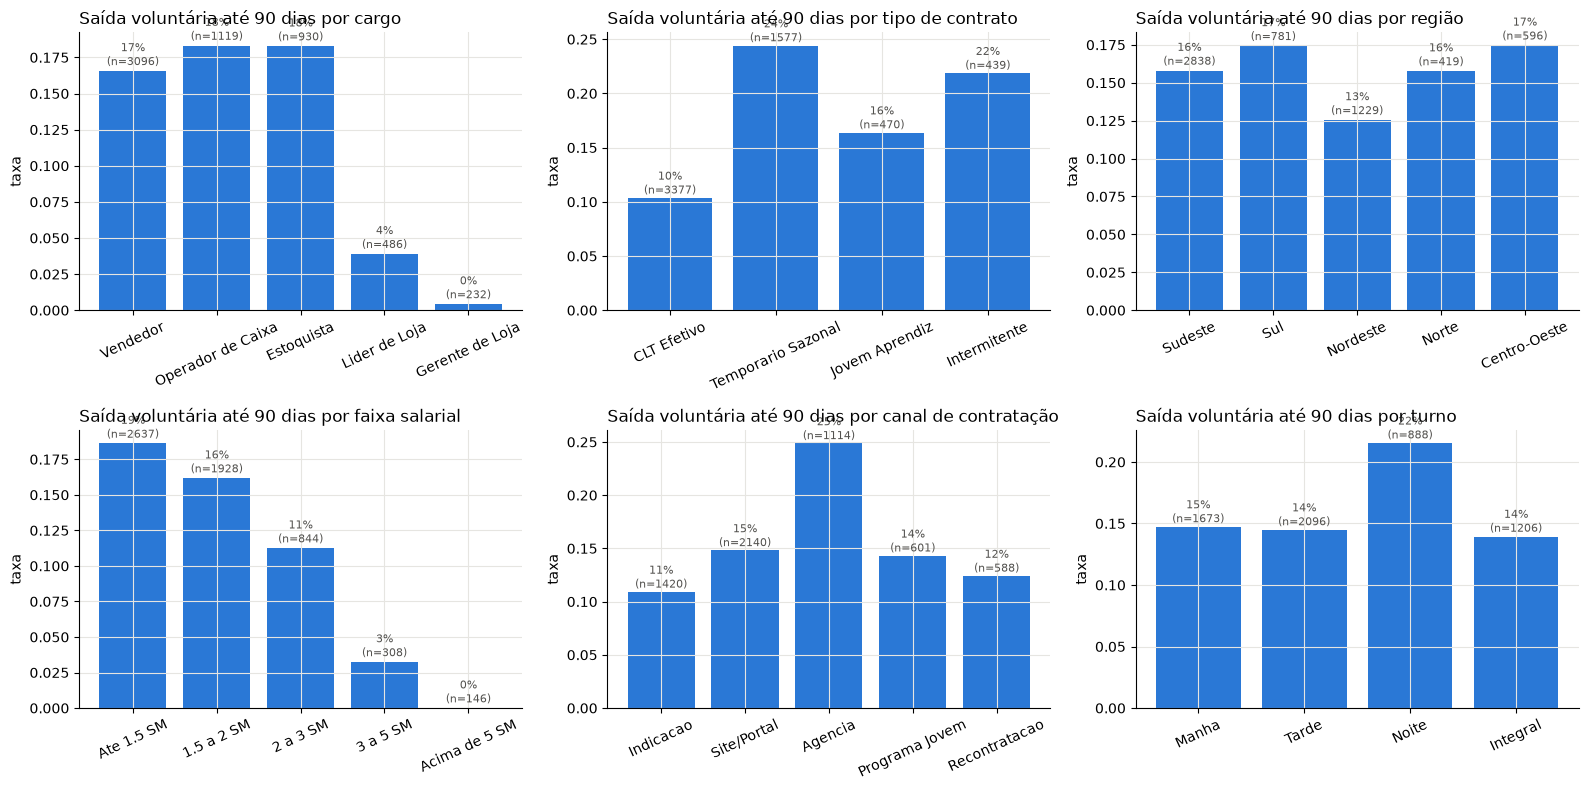

In [5]:
base = t.montar_base_analitica(colab, lojas)
pop90 = t.populacao_treino(base, 90)
pop180 = t.populacao_treino(base, 180)
print(f"População 90d: {len(pop90)} (taxa y90 = {pop90['y90'].mean():.3f}) | População 180d: {len(pop180)} (taxa y180 = {pop180['y180'].mean():.3f})")
print(f"Status geral: {colab['status'].value_counts().to_dict()} | tipo de desligamento: {colab['tipo_desligamento'].value_counts().to_dict()}")

def taxa_por(df, col, alvo="y90", ordem=None):
    g = df.groupby(col)[alvo].agg(["mean", "size"]).rename(columns={"mean": "taxa", "size": "n"})
    return g.reindex(ordem) if ordem else g.sort_values("taxa", ascending=False)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
dimensoes = [("cargo", t.ORDEM_CATEGORIAS["cargo"]), ("tipo_contrato", t.ORDEM_CATEGORIAS["tipo_contrato"]),
             ("regiao", t.ORDEM_CATEGORIAS["regiao"]), ("faixa_salarial", t.ORDEM_CATEGORIAS["faixa_salarial"]),
             ("canal_contratacao", t.ORDEM_CATEGORIAS["canal_contratacao"]), ("turno", t.ORDEM_CATEGORIAS["turno"])]
for ax, (col, ordem) in zip(axes.ravel(), dimensoes):
    g = taxa_por(pop90, col, ordem=ordem)
    ax.bar(g.index, g["taxa"], color=CORES[0])
    ax.set_title(f"Saída voluntária até 90 dias por {rc.ROTULOS[col].lower()}")
    ax.set_ylabel("taxa")
    ax.tick_params(axis="x", rotation=25)
    for i, (v, n) in enumerate(zip(g["taxa"], g["n"])):
        ax.text(i, v + 0.004, f"{v:.0%}\n(n={n})", ha="center", fontsize=8, color=rc.COR_TEXTO_SEC)
plt.tight_layout(); plt.show()

### 4.2 Distância, integração e avaliação de experiência

Três sinais operacionais com forte relação com a saída precoce: a distância casa-trabalho, a conclusão da
trilha de integração até o dia 30 e a avaliação de experiência.

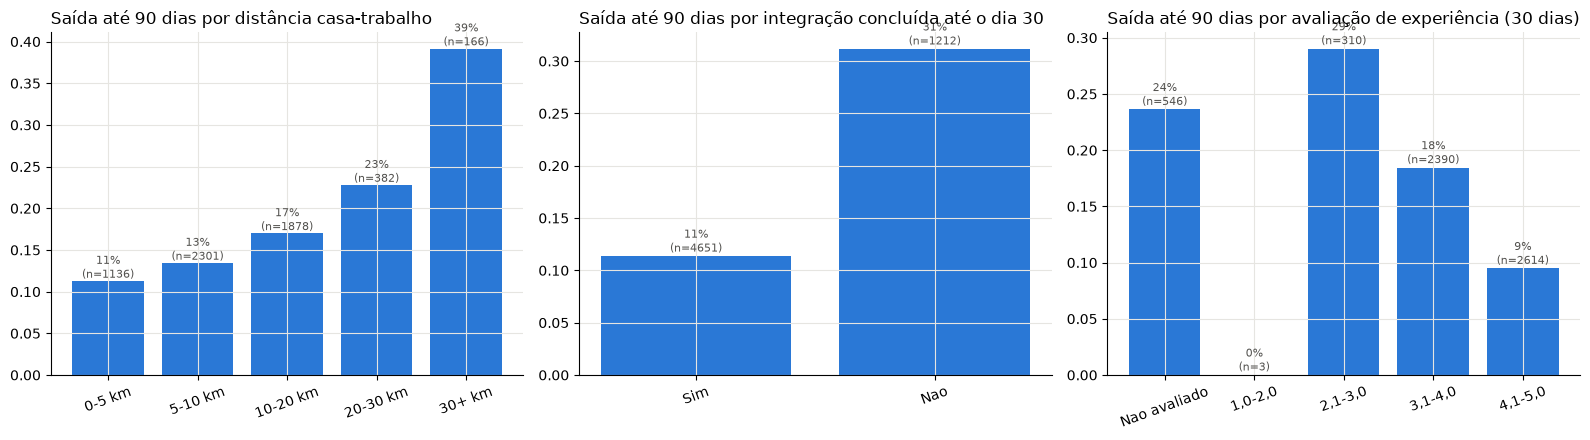

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["distancia_casa_trabalho_km", "onboarding_concluido", "avaliacao_experiencia_30d"]):
    cats = t.categorizar_fator(col, pop90[col])
    ordem = t.ordem_categorias(col)
    g = pop90.assign(cat=cats).groupby("cat")["y90"].agg(["mean", "size"]).reindex(ordem).dropna()
    ax.bar(g.index.astype(str), g["mean"], color=CORES[0])
    ax.set_title(f"Saída até 90 dias por {rc.ROTULOS[col].lower()}")
    for i, (v, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, v + 0.004, f"{v:.0%}\n(n={int(n)})", ha="center", fontsize=8, color=rc.COR_TEXTO_SEC)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

### 4.3 Sazonalidade mensal

As admissões têm picos em **setembro/outubro (Dia das Crianças)** e **novembro/dezembro (Natal)**, com
predominância de contratos temporários sazonais. As saídas voluntárias seguem as admissões com defasagem
de 1 a 3 meses.

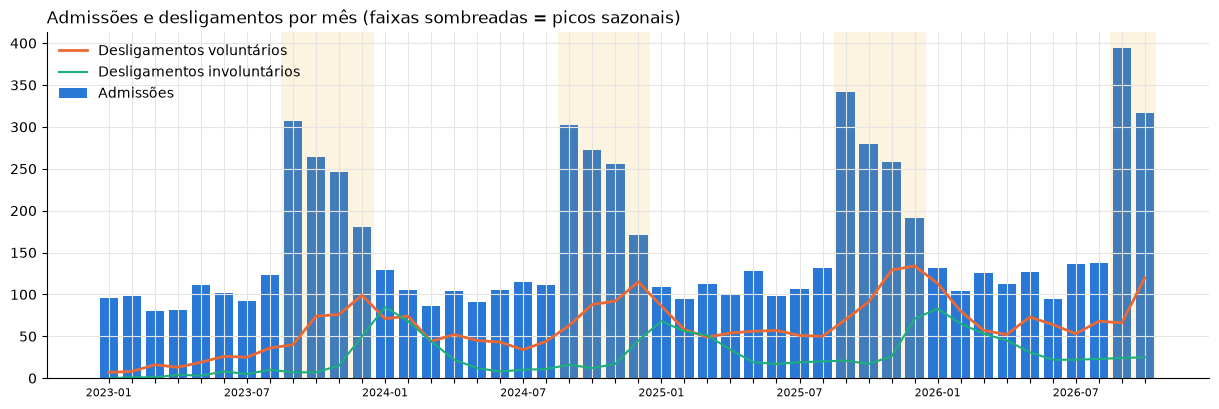

mes,1,2,3,4,5,6,7,8,9,10,11,12
proporcao_temporarios_por_mes_de_admissao,0.08,0.07,0.09,0.08,0.08,0.08,0.08,0.06,0.51,0.54,0.52,0.51


In [7]:
tm = t.turnover_mensal(colab)
fig, ax = plt.subplots(figsize=(15, 4.5))
x = np.arange(len(tm))
ax.bar(x, tm["admissoes"], color=CORES[0], label="Admissões")
ax.plot(x, tm["desligamentos_voluntarios"], color=CORES[1], linewidth=2, label="Desligamentos voluntários")
ax.plot(x, tm["desligamentos_involuntarios"], color=CORES[2], linewidth=1.5, label="Desligamentos involuntários")
for i, p in enumerate(tm["periodo_pico"]):
    if p:
        ax.axvspan(i - 0.5, i + 0.5, color=CORES[3], alpha=0.12, linewidth=0)
ax.set_xticks(x); ax.set_xticklabels([d.strftime("%Y-%m") if d.month in (1, 7) else "" for d in tm["mes"]], fontsize=8)
ax.set_title("Admissões e desligamentos por mês (faixas sombreadas = picos sazonais)"); ax.legend(frameon=False)
plt.show()
temp = colab.assign(mes=colab["data_admissao"].dt.month).groupby("mes")["tipo_contrato"].apply(lambda s: (s == "Temporario Sazonal").mean())
display(temp.rename("proporcao_temporarios_por_mes_de_admissao").to_frame().T.round(2))

### 4.4 Motivos declarados de saída voluntária

Motivos registrados na entrevista de desligamento (últimos 12 meses). "Falta de adaptação", "nova oportunidade"
e "horário/escala" lideram — coerente com o peso da integração e da escala entre os fatores de risco.

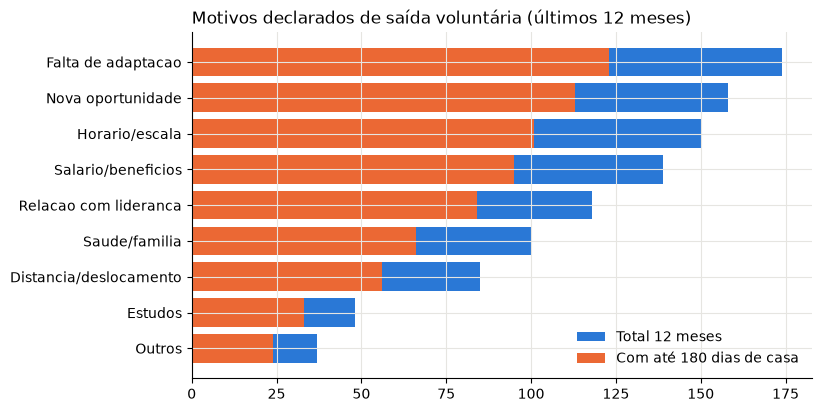

In [8]:
ref = rc.DATA_REFERENCIA
m = (colab["tipo_desligamento"] == "Voluntario") & (colab["data_desligamento"] > ref - rc.dias(365))
motivos = colab[m].groupby("motivo_desligamento").agg(n=("colaborador_id", "size"), ate_180d=("dias_de_casa", lambda s: (s <= 180).sum())).sort_values("n")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(motivos.index, motivos["n"], color=CORES[0], label="Total 12 meses")
ax.barh(motivos.index, motivos["ate_180d"], color=CORES[1], label="Com até 180 dias de casa")
ax.set_title("Motivos declarados de saída voluntária (últimos 12 meses)"); ax.legend(frameon=False)
plt.show()

### 4.5 Curva de permanência (Kaplan-Meier)

Evento = saída voluntária; censura = ativo na referência ou saída involuntária/fim de contrato. A queda é
mais acentuada nos primeiros 90 dias, sobretudo entre temporários sazonais e intermitentes.

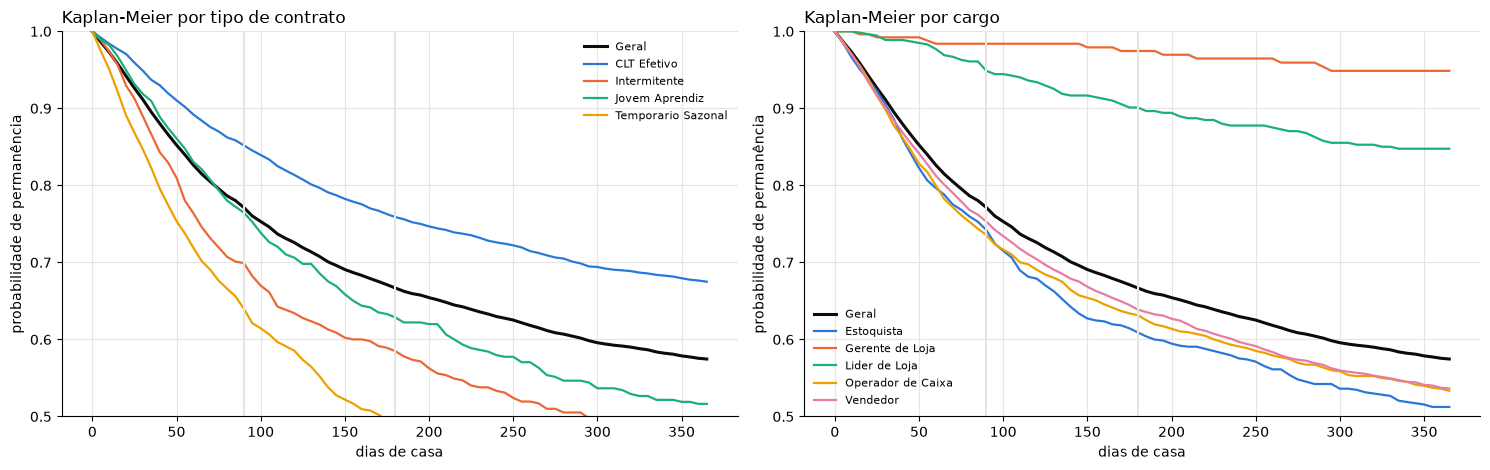

In [9]:
curva = t.curvas_sobrevivencia(colab, lojas)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, seg in zip(axes, ["tipo_contrato", "cargo"]):
    geral = curva[curva["segmento_tipo"] == "geral"]
    ax.plot(geral["dia"], geral["prob_permanencia"], color=rc.COR_TEXTO, linewidth=2.2, label="Geral")
    for i, (valor, g) in enumerate(curva[curva["segmento_tipo"] == seg].groupby("segmento_valor")):
        ax.plot(g["dia"], g["prob_permanencia"], color=CORES[i], linewidth=1.6, label=valor)
    for d in (90, 180):
        ax.axvline(d, color=rc.COR_GRADE)
    ax.set_ylim(0.5, 1); ax.set_xlabel("dias de casa"); ax.set_ylabel("probabilidade de permanência")
    ax.set_title(f"Kaplan-Meier por {rc.ROTULOS[seg].lower()}"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 5. Construção das variáveis e dos alvos

* **Checkpoint**: dia 30 de casa. Só entram no modelo informações disponíveis até esse ponto.
* **Alvos**: `y90` = saída voluntária com `dias_de_casa <= 90`; `y180` idem com 180. Saídas involuntárias
  e fins de contrato antes do horizonte recebem rótulo 0 (limitação: risco competitivo).
* **População de treino**: janela completa (admissão <= referência − horizonte) e `dias_de_casa >= 30`.
* **Preditoras** (23): atributos de admissão, da loja (agregados) e sinais dos primeiros 30 dias, mais o
  indicador `avaliacao_experiencia_30d_ausente`. `faixa_etaria` e `loja_id` ficam **fora** do modelo.
* **Pré-processamento**: imputação pela média + padronização (regressão logística) e one-hot
  (`handle_unknown='ignore'`) para categóricas; árvores recebem one-hot sem padronização.

In [10]:
X90 = t.preparar_X(pop90)
print("Variáveis preditoras:", len(rc.FEATURES))
print("Categóricas:", rc.FEATURES_CAT)
print("Numéricas/booleanas:", rc.FEATURES_NUM)
display(X90.head())
m_tr, m_te = t.dividir_temporal(pop90)
print(f"Divisão temporal 90d: treino {m_tr.sum()} (admissões até 2025-12-31, taxa {pop90['y90'][m_tr].mean():.3f}) | teste {m_te.sum()} (2026, taxa {pop90['y90'][m_te].mean():.3f})")

Variáveis preditoras: 24
Categóricas: ['cargo', 'tipo_contrato', 'faixa_salarial', 'escolaridade', 'turno', 'canal_contratacao', 'mes_admissao', 'bandeira', 'tipo_loja', 'regiao', 'porte']
Numéricas/booleanas: ['carga_horaria_semanal', 'experiencia_previa_varejo', 'distancia_casa_trabalho_km', 'admitido_periodo_pico', 'onboarding_concluido', 'horas_treinamento_30d', 'avaliacao_experiencia_30d', 'avaliacao_experiencia_30d_ausente', 'faltas_30d', 'atrasos_30d', 'horas_extras_media_semana', 'gestor_tempo_cargo_meses', 'turnover_loja_12m']


,cargo,tipo_contrato,faixa_salarial,escolaridade,turno,canal_contratacao,mes_admissao,bandeira,tipo_loja,regiao,porte,carga_horaria_semanal,experiencia_previa_varejo,distancia_casa_trabalho_km,admitido_periodo_pico,onboarding_concluido,horas_treinamento_30d,avaliacao_experiencia_30d,avaliacao_experiencia_30d_ausente,faltas_30d,atrasos_30d,horas_extras_media_semana,gestor_tempo_cargo_meses,turnover_loja_12m
0,Vendedor,CLT Efetivo,1.5 a 2 SM,Superior Incompleto,Tarde,Programa Jovem,1,PBKids,Outlet,Sudeste,Media,44.0,0.0,9.6,0.0,0.0,11.9,3.2,0.0,0.0,1.0,1.1,22.0,0.3969
1,Operador de Caixa,CLT Efetivo,Ate 1.5 SM,Medio,Noite,Site/Portal,1,PBKids,Shopping,Sudeste,Grande,44.0,0.0,27.2,0.0,0.0,9.2,4.2,0.0,2.0,6.0,3.0,7.0,0.2690
2,Lider de Loja,CLT Efetivo,3 a 5 SM,Superior Completo,Tarde,Indicacao,1,Ri Happy,Shopping,Sudeste,Grande,36.0,1.0,19.6,0.0,1.0,27.8,NaN,1.0,0.0,0.0,0.8,19.0,0.4423
4,Vendedor,CLT Efetivo,1.5 a 2 SM,Superior Completo,Tarde,Indicacao,1,Ri Happy,Rua,Nordeste,Pequena,44.0,1.0,14.9,0.0,0.0,8.3,2.9,0.0,1.0,1.0,2.7,50.0,0.3522
5,Estoquista,Jovem Aprendiz,Ate 1.5 SM,Superior Incompleto,Noite,Programa Jovem,1,Newtoys,Shopping,Nordeste,Media,20.0,0.0,2.1,0.0,1.0,5.2,4.1,0.0,2.0,1.0,2.8,34.0,0.4995


Divisão temporal 90d: treino 5066 (admissões até 2025-12-31, taxa 0.163) | teste 797 (2026, taxa 0.100)


## 6. Treino e comparação dos quatro modelos

Regressão logística (baseline interpretável), random forest, gradient boosting (HistGradientBoosting) e
XGBoost. Métricas no **teste temporal** (admissões de 2026) e AUC médio da **validação cruzada estratificada
(5 folds)** no treino. Regra de seleção: maior AUC-ROC; a regressão logística vence se ficar a menos de 0,01
do melhor modelo (parcimônia e interpretabilidade).

In [11]:
treinos, selecionados = {}, {}
linhas = []
for hz, h in rc.HORIZONTES.items():
    pop = t.populacao_treino(base, h)
    treinos[hz] = t.treinar_e_avaliar(pop, h)
    selecionados[hz] = t.selecionar_modelo(treinos[hz]["resultados"])
    for nome, r in treinos[hz]["resultados"].items():
        linhas.append({"horizonte": hz, "modelo": rc.MODELOS_NOMES[nome], "selecionado": nome == selecionados[hz], **r["metricas"]})
metricas = pd.DataFrame(linhas).set_index(["horizonte", "modelo"])
display(metricas.round(4))
print("Selecionados:", selecionados)

[90d] treino=5066 (taxa 0.163) | teste=797 (taxa 0.100)


[90d] regressao_logistica: AUC teste 0.805 | AUC-PR 0.450 | CV 0.823±0.010 | 0.5s


[90d] random_forest: AUC teste 0.782 | AUC-PR 0.377 | CV 0.801±0.016 | 3.5s


[90d] gradient_boosting: AUC teste 0.808 | AUC-PR 0.482 | CV 0.802±0.012 | 2.8s


[90d] xgboost: AUC teste 0.803 | AUC-PR 0.489 | CV 0.805±0.012 | 1.9s
[180d] treino=5066 (taxa 0.260) | teste=466 (taxa 0.217)


[180d] regressao_logistica: AUC teste 0.824 | AUC-PR 0.609 | CV 0.818±0.012 | 0.4s


[180d] random_forest: AUC teste 0.804 | AUC-PR 0.567 | CV 0.801±0.010 | 3.4s


[180d] gradient_boosting: AUC teste 0.813 | AUC-PR 0.601 | CV 0.804±0.008 | 2.8s


[180d] xgboost: AUC teste 0.822 | AUC-PR 0.631 | CV 0.809±0.008 | 1.7s


selecionado  auc_roc  auc_pr   brier  recall_top20  precisao_top20      f1  limiar_f1  taxa_base  auc_cv_media  \
horizonte modelo                                                                                                                                       
90d       Regressão logística                True   0.8046  0.4500  0.0739        0.5875          0.2938  0.4474     0.3223     0.1004        0.8227   
          Random forest                     False   0.7820  0.3765  0.0798        0.5750          0.2875  0.4131     0.2072     0.1004        0.8008   
          Gradient boosting (HistGB)        False   0.8083  0.4821  0.0717        0.5750          0.2875  0.4795     0.3464     0.1004        0.8016   
          XGBoost                           False   0.8026  0.4889  0.0717        0.5500          0.2750  0.4870     0.4545     0.1004        0.8049   
180d      Regressão logística                True   0.8237  0.6090  0.1246        0.5347          0.5745  0.5854     0.3431     0.2167        0.8180   
          Random forest                     False   0.8037  0.5669  0.1374        0.5050          0.5426  0.5590     0.2944     0.2167        0.8013   
          Gradient boosting (HistGB)        False   0.8127  0.6015  0.1287        0.4851          0.5213  0.5654     0.2931     0.2167        0.8038   
          XGBoost                           False   0.8218  0.6311  0.1244        0.5050          0.5426  0.5588     0.2203     0.2167        0.8094   

                                      auc_cv_desvio  
horizonte modelo                                     
90d       Regressão logística                0.0099  
          Random forest                      0.0157  
          Gradient boosting (HistGB)         0.0117  
          XGBoost                            0.0115  
180d      Regressão logística                0.0120  
          Random forest                      0.0095  
          Gradient boosting (HistGB)         0.0075  
          XGBoost                            0.0084

Selecionados: {'90d': 'regressao_logistica', '180d': 'regressao_logistica'}


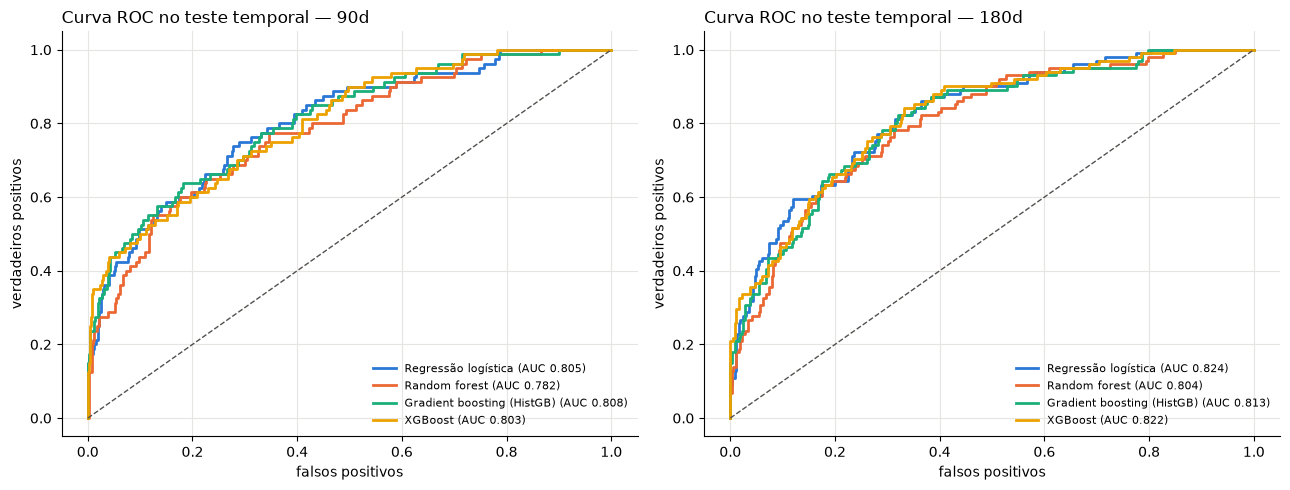

In [12]:
from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (hz, tr) in zip(axes, treinos.items()):
    y_te = tr["y"][tr["m_teste"]]
    for i, nome in enumerate(t.ORDEM_MODELOS):
        r = tr["resultados"][nome]
        fpr, tpr, _ = roc_curve(y_te, r["p_teste"])
        ax.plot(fpr, tpr, color=CORES[i], linewidth=2, label=f"{rc.MODELOS_NOMES[nome]} (AUC {r['metricas']['auc_roc']:.3f})")
    ax.plot([0, 1], [0, 1], "--", color=rc.COR_TEXTO_SEC, linewidth=1)
    ax.set_title(f"Curva ROC no teste temporal — {hz}"); ax.set_xlabel("falsos positivos"); ax.set_ylabel("verdadeiros positivos")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 7. Explicabilidade (SHAP)

Importância global = média |contribuição| por variável (SHAP agregado sobre as colunas one-hot). Para a
regressão logística as contribuições são `coef × (x_padronizado − média)` (equivalentes ao LinearExplainer);
para os modelos de árvore usa-se `shap.TreeExplainer`. Abaixo, o modelo selecionado em cada horizonte e,
para comparação, o XGBoost no horizonte de 90 dias.

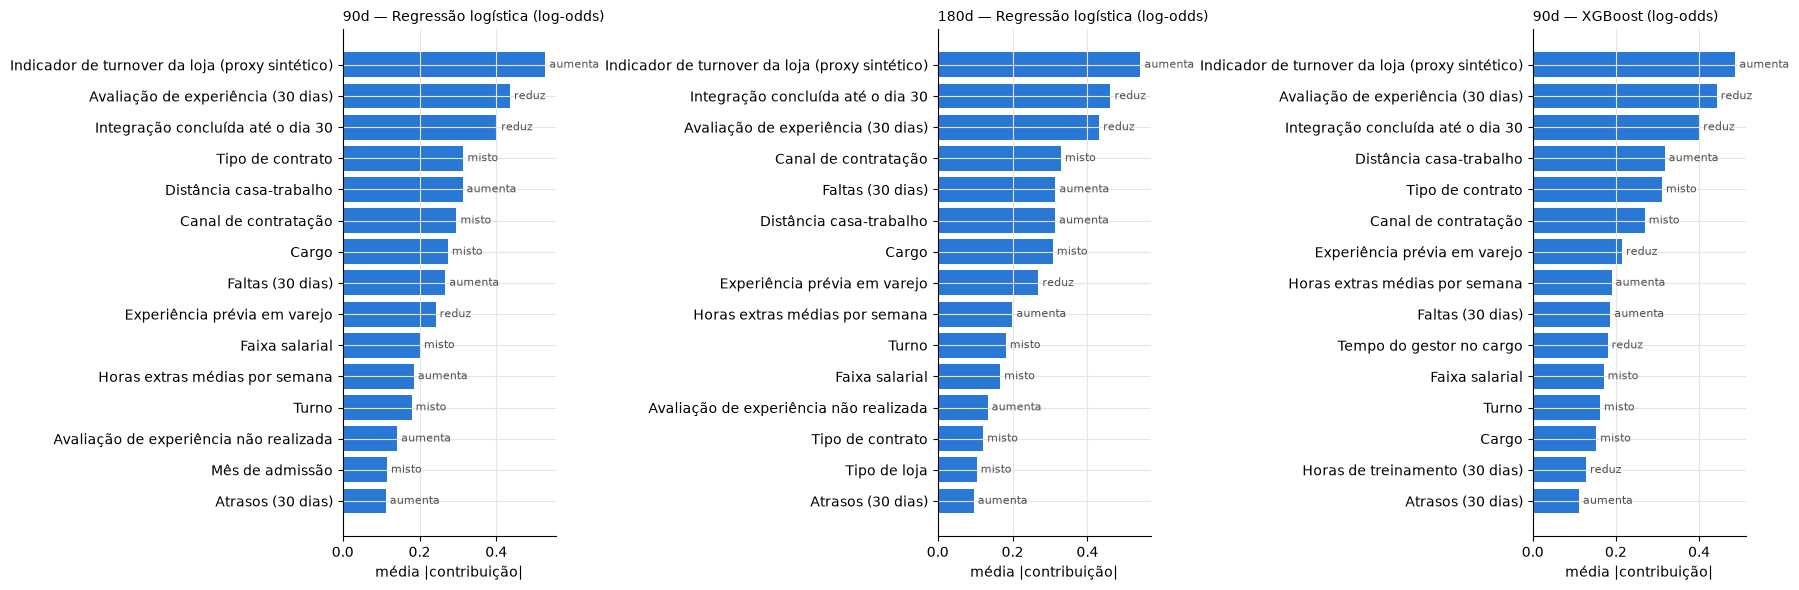

In [13]:
rng = np.random.default_rng(rc.SEMENTE)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
paineis = [("90d", selecionados["90d"]), ("180d", selecionados["180d"]), ("90d", "xgboost")]
for ax, (hz, nome) in zip(axes, paineis):
    tr = treinos[hz]
    X_tr = tr["X"][tr["m_treino"]]
    amostra = X_tr.iloc[rng.choice(len(X_tr), size=min(1000, len(X_tr)), replace=False)]
    contrib, metodo, escala = t.contribuicoes_por_variavel(tr["resultados"][nome]["pipeline"], nome, amostra, X_tr)
    fg = t.fatores_globais(contrib, amostra, hz, False).sort_values("importancia")
    ax.barh(fg["rotulo"], fg["importancia"], color=CORES[0])
    for i, (v, d) in enumerate(zip(fg["importancia"], fg["direcao"])):
        ax.text(v, i, f" {d}", va="center", fontsize=8, color=rc.COR_TEXTO_SEC)
    ax.set_title(f"{hz} — {rc.MODELOS_NOMES[nome]} ({escala})", fontsize=10)
    ax.set_xlabel("média |contribuição|")
plt.tight_layout(); plt.show()

### 7.1 Explicação individual

Para cada colaborador escorado, os três fatores de maior |contribuição| (com direção e valor) alimentam a
lista priorizada do dashboard e a ação recomendada do playbook. O exemplo carrega os modelos publicados
(`pipeline/modelos/modelo_90d.joblib` e `modelo_180d.joblib`), treinados em treino + teste, e aplica a regra
do risco vigente: até o dia 90 vale o risco de 90 dias; depois dele, o risco residual até o dia 180.

In [14]:
escorados = t.populacao_escorada(base)
X_esc = t.preparar_X(escorados)
import joblib
publicados = {hz: joblib.load(rc.DIR_MODELOS / f"modelo_{hz}.joblib") for hz in rc.HORIZONTES}
contribs = {}
for hz, h in rc.HORIZONTES.items():
    X_all = treinos[hz]["X"]
    idx_fundo = np.random.default_rng(rc.SEMENTE).choice(len(X_all), size=min(t.AMOSTRA_SHAP_GLOBAL, len(X_all)), replace=False)
    contribs[hz], _, _ = t.contribuicoes_por_variavel(publicados[hz], selecionados[hz], X_esc, X_all.iloc[idx_fundo])
p90 = publicados["90d"].predict_proba(X_esc)[:, 1]
p180 = publicados["180d"].predict_proba(X_esc)[:, 1]
dias_casa = escorados["dias_de_casa"].astype(int).to_numpy()
vigente = np.array([rc.risco_vigente(round(a, 4), round(b, 4), d) for a, b, d in zip(p90, p180, dias_casa)])
print(f"Escorados: {len(escorados)} | já passaram do dia 90: {(dias_casa > 90).sum()}")
exemplos = np.argsort(-vigente)[:3]
for i in exemplos:
    linha = escorados.iloc[i]
    hz = "90d" if dias_casa[i] <= 90 else "180d"
    fatores = t.fatores_top_individuais(contribs[hz].iloc[i], linha)
    nivel = rc.nivel_risco(round(float(vigente[i]), 4))
    print(f"{linha['colaborador_id']} | {linha['cargo']} | {linha['tipo_contrato']} | {dias_casa[i]} dias | risco vigente {vigente[i]:.2f} ({nivel}) | risco 90d {p90[i]:.2f} | risco 180d {p180[i]:.2f}")
    for f in fatores:
        print(f"   - {f['rotulo']}: {f['valor']} ({f['direcao']}, {f['contribuicao']:+.2f})")
    print("   Ação:", rc.montar_acao_recomendada(nivel, fatores, linha.to_dict()))

Escorados: 701 | já passaram do dia 90: 260
C006785 | Operador de Caixa | Temporario Sazonal | 43 dias | risco vigente 0.92 (Critico) | risco 90d 0.92 | risco 180d 0.95
   - Avaliação de experiência (30 dias): 2,3 / 5 (aumenta, +1.70)
   - Integração não concluída: Não (aumenta, +1.01)
   - Distância casa-trabalho: 22 km (aumenta, +0.67)
   Ação: Conversa de retenção líder + RH em 48h | Conversa de feedback estruturada (1:1) e plano de desenvolvimento de 30 dias
C006617 | Estoquista | Temporario Sazonal | 55 dias | risco vigente 0.87 (Critico) | risco 90d 0.87 | risco 180d 0.92
   - Integração não concluída: Não (aumenta, +1.01)
   - Canal de contratação: Agencia (aumenta, +0.63)
   - Horas extras médias por semana: 11,3 h/semana (aumenta, +0.54)
   Ação: Conversa de retenção líder + RH em 48h | Concluir trilha de integração com acompanhamento do líder
C006875 | Vendedor | Temporario Sazonal | 35 dias | risco vigente 0.87 (Critico) | risco 90d 0.87 | risco 180d 0.93
   - Integração não

## 8. Calibração

Risco médio previsto × taxa real por decil no teste temporal (modelo selecionado). Em 90 dias o modelo fica
calibrado nos extremos, mas as faixas Médio (0,15 a 0,30) e Alto (0,30 a 0,45) ficam superestimadas nesse teste,
que não tem admissões de pico. Em 180 dias a calibração é melhor. Por isso os limiares de nível são faixas de
priorização, não probabilidades exatas.

,decil,n,risco_medio_previsto,taxa_real,limite_inf,limite_sup,horizonte
0,1,80,0.0037,0.0000,0.0003,0.0076,90d
1,2,80,0.0121,0.0250,0.0077,0.0158,90d
2,3,79,0.0203,0.0380,0.0159,0.0263,90d
3,4,80,0.0341,0.0375,0.0263,0.0427,90d
4,5,80,0.0538,0.0250,0.0438,0.0658,90d
5,6,79,0.0815,0.0886,0.0659,0.0934,90d
6,7,80,0.1072,0.1125,0.0937,0.1245,90d
7,8,79,0.1567,0.0886,0.1253,0.1942,90d
8,9,80,0.2449,0.1625,0.1944,0.3061,90d
9,10,80,0.4600,0.4250,0.3072,0.8224,90d


,nivel,n,risco_medio_previsto,taxa_real,horizonte
0,Baixo,593,0.0501,0.0506,90d
1,Medio,119,0.2158,0.1345,90d
2,Alto,49,0.3568,0.2653,90d
3,Critico,36,0.5788,0.5833,90d


,decil,n,risco_medio_previsto,taxa_real,limite_inf,limite_sup,horizonte
0,1,47,0.0073,0.0000,0.0006,0.0135,180d
1,2,47,0.0243,0.0426,0.0141,0.0351,180d
2,3,46,0.0482,0.0870,0.0359,0.0597,180d
3,4,47,0.0759,0.0851,0.0606,0.0953,180d
4,5,46,0.1159,0.0652,0.0961,0.1384,180d
5,6,47,0.1690,0.2128,0.1390,0.2026,180d
6,7,46,0.2363,0.2826,0.2029,0.2660,180d
7,8,47,0.3142,0.2340,0.2661,0.3689,180d
8,9,46,0.4620,0.4783,0.3820,0.5450,180d
9,10,47,0.6899,0.6809,0.5461,0.9557,180d


,nivel,n,risco_medio_previsto,taxa_real,horizonte
0,Baixo,244,0.0581,0.0574,180d
1,Medio,100,0.2234,0.2600,180d
2,Alto,49,0.3672,0.3061,180d
3,Critico,73,0.6213,0.6301,180d


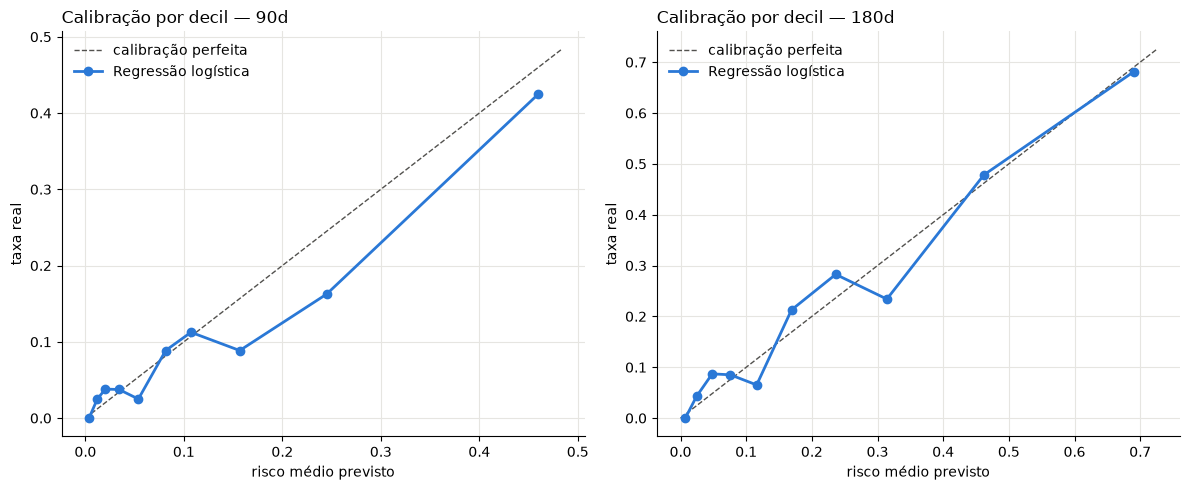

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (hz, tr) in zip(axes, treinos.items()):
    nome = selecionados[hz]
    y_te = tr["y"][tr["m_teste"]]
    tab = t.calibracao_por_decil(y_te, tr["resultados"][nome]["p_teste"])
    lim = max(tab["risco_medio_previsto"].max(), tab["taxa_real"].max()) * 1.05
    ax.plot([0, lim], [0, lim], "--", color=rc.COR_TEXTO_SEC, linewidth=1, label="calibração perfeita")
    ax.plot(tab["risco_medio_previsto"], tab["taxa_real"], marker="o", color=CORES[0], linewidth=2, label=rc.MODELOS_NOMES[nome])
    ax.set_title(f"Calibração por decil — {hz}"); ax.set_xlabel("risco médio previsto"); ax.set_ylabel("taxa real"); ax.legend(frameon=False)
    display(tab.assign(horizonte=hz))
    display(t.calibracao_por_nivel(y_te, tr["resultados"][nome]["p_teste"]).assign(horizonte=hz))
plt.tight_layout(); plt.show()

### 8.1 Validação retroativa com picos

O teste temporal oficial (admissões de 2026 com janela completa) **não contém nenhuma admissão de pico**, enquanto
mais da metade do treino é de pico. Para medir esse regime, a regressão logística é treinada com admissões até 2024 e
testada nas admissões de 2025. Essa validação não altera os modelos publicados.

In [16]:
for hz in rc.HORIZONTES:
    pop_h = t.populacao_treino(base, rc.HORIZONTES[hz])
    _, m = t.dividir_temporal(pop_h)
    print(f"Teste oficial {hz}: {m.sum()} admissões, {pop_h.loc[m, 'admitido_periodo_pico'].astype(bool).sum()} de pico, até {pop_h.loc[m, 'data_admissao'].max().date()}")
display(t.validacao_retroativa(base))

Teste oficial 90d: 797 admissões, 0 de pico, até 2026-08-02
Teste oficial 180d: 466 admissões, 0 de pico, até 2026-05-04


,horizonte,recorte,n,taxa_real,risco_medio_previsto,auc_roc
0,90d,Geral,1757,0.1685,0.1593,0.8342
1,90d,Admissões de pico,926,0.2214,0.1979,0.8191
2,90d,Admissões fora do pico,831,0.1095,0.1162,0.8266
3,90d,Temporários sazonais,529,0.2836,0.2421,0.8002
4,180d,Geral,1757,0.2669,0.2502,0.8242
5,180d,Admissões de pico,926,0.3186,0.2956,0.8099
6,180d,Admissões fora do pico,831,0.2094,0.1997,0.8284
7,180d,Temporários sazonais,529,0.3497,0.3299,0.8063


## 9. Auditoria de viés

`faixa_etaria` não entra como preditor, mas o desempenho é auditado por faixa etária, região e
escolaridade, com previsões **fora da amostra** (validação cruzada em treino + teste). Buscamos taxa prevista
próxima da real e AUC semelhante entre grupos; `taxa_alto_risco` é a proporção com risco >= 0,30.

In [17]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
vies = []
for hz, h in rc.HORIZONTES.items():
    tr = treinos[hz]
    pop = t.populacao_treino(base, h)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=rc.SEMENTE)
    p_oof = cross_val_predict(clone(tr["resultados"][selecionados[hz]]["pipeline"]), tr["X"], tr["y"], cv=cv, method="predict_proba")[:, 1]
    vies.append(t.avaliacao_vies(pop, p_oof, hz, h))
vies = pd.concat(vies, ignore_index=True)
display(vies[vies["horizonte"] == "90d"].set_index(["grupo_tipo", "grupo_valor"]).drop(columns="horizonte"))
fx = vies[vies["grupo_tipo"] == "faixa_etaria"].assign(dif_pp=lambda d: 100 * (d["risco_medio_previsto"] - d["taxa_real"]))
display(fx[["horizonte", "grupo_valor", "n", "taxa_real", "risco_medio_previsto", "dif_pp", "taxa_alto_risco"]].round(3))

n  taxa_real  risco_medio_previsto     auc  taxa_alto_risco
grupo_tipo   grupo_valor                                                                        
faixa_etaria 18-24                2326     0.1879                0.1714  0.8132           0.1874
             25-34                1825     0.1425                0.1492  0.8170           0.1693
             35-44                1019     0.1217                0.1380  0.8732           0.1501
             45-54                 482     0.1452                0.1483  0.8130           0.1722
             55+                   211     0.0806                0.1295  0.7953           0.1469
regiao       Sudeste              2838     0.1579                0.1583  0.8313           0.1734
             Sul                   781     0.1741                0.1732  0.8156           0.2049
             Nordeste             1229     0.1253                0.1273  0.8276           0.1408
             Norte                 419     0.1575                0.1570  0.8278           0.1599
             Centro-Oeste          596     0.1745                0.1741  0.7936           0.2013
escolaridade Fundamental           382     0.1283                0.1312  0.7933           0.1309
             Medio                2843     0.1643                0.1651  0.8063           0.1942
             Superior Incompleto  1979     0.1491                0.1488  0.8393           0.1501
             Superior Completo     659     0.1472                0.1466  0.8768           0.1715

,horizonte,grupo_valor,n,taxa_real,risco_medio_previsto,dif_pp,taxa_alto_risco
0,90d,18-24,2326,0.188,0.171,-1.65,0.187
1,90d,25-34,1825,0.142,0.149,0.67,0.169
2,90d,35-44,1019,0.122,0.138,1.63,0.150
3,90d,45-54,482,0.145,0.148,0.31,0.172
4,90d,55+,211,0.081,0.130,4.89,0.147
14,180d,18-24,2196,0.312,0.288,-2.41,0.389
15,180d,25-34,1734,0.235,0.243,0.80,0.316
16,180d,35-44,951,0.196,0.228,3.29,0.293
17,180d,45-54,455,0.244,0.240,-0.37,0.312
18,180d,55+,196,0.153,0.210,5.73,0.235


**O que a auditoria encontrou.** A faixa **55+ fica superestimada** (90 dias: previsto 13,0% contra real 8,1%; 180 dias:
21,0% contra 15,3%, acima do alerta de 5 p.p. do dashboard), o que gera excesso de alertas para o grupo. A faixa
**18-24 fica subestimada** nos dois horizontes (90 dias: 17,1% contra 18,8%; 180 dias: 28,8% contra 31,2%), o que pode
deixar casos sem atenção. Embora a idade não entre no modelo, `tipo_contrato` (Jovem Aprendiz) e `canal_contratacao`
(Programa Jovem) estão ligados a ela e funcionam como proxies. **Ação:** revisar com Gente & Gestão antes de qualquer
uso e avaliar recalibração por grupo na Sprint 2.

## 10. Conclusões

* Os quatro modelos atingem AUC-ROC entre ~0,78 e ~0,83 no teste temporal; a **regressão logística** fica a
  menos de 0,01 do melhor e é selecionada pela regra de parcimônia — o simulador do dashboard é, portanto, o
  próprio modelo oficial.
* Os fatores mais importantes são operacionais e **acionáveis**: turnover da loja, avaliação de experiência,
  integração concluída, distância casa-trabalho, canal de contratação (agência), contrato temporário e faltas
  nos primeiros 30 dias.
* A sazonalidade concentra admissões e saídas precoces nas campanhas de Dia das Crianças e Natal, quando a
  proporção de temporários é maior.
* A auditoria encontrou descalibração por idade (55+ superestimada e 18-24 subestimada), a ser revista com
  Gente & Gestão antes de qualquer uso.
* Os efeitos dos fatores foram parametrizados no gerador da base sintética: confirmam que o método recupera o
  mecanismo simulado, mas não são achados sobre a Ri Happy.

## 11. Recomendações (playbook)

| Gatilho | Ação | Responsável | Prazo |
|---|---|---|---|
| Integração não concluída | Concluir trilha de integração com acompanhamento do líder | Líder de loja | 7 dias |
| Avaliação de experiência <= 2,5 | Conversa de feedback estruturada (1:1) e plano de desenvolvimento de 30 dias | Líder + BP RH | 7 dias |
| Distância >= 20 km | Avaliar transferência, ajuste de escala e apoio de transporte | BP RH | 15 dias |
| Faltas >= 2 ou atrasos >= 3 | Conversa de acolhimento e ajuste de escala | Líder de loja | 5 dias |
| Temporário sazonal | Comunicar critérios de efetivação e trilha de carreira | BP RH | 10 dias |
| Indicador de turnover da loja >= 45% | Diagnóstico de clima da loja e plano de ação | Gerente regional + RH | 30 dias |
| Nível Crítico / Alto / Médio | Conversa de retenção em 48h / plano individual em 7 dias / acompanhamento quinzenal | Líder + RH | 2-15 dias |

A tabela completa está em `rr_recomendacoes`; a economia potencial usa `rr_parametros_custo`
(≈ R$ 6.500 por desligamento precoce, premissa ilustrativa).

## 12. Limitações e uso responsável

* **Dados sintéticos**: as relações refletem um mecanismo plausível, não a realidade da Ri Happy; os
  resultados devem ser reestimados com a base real (pseudonimizada) antes de qualquer decisão.
* **Risco competitivo**: saídas involuntárias e fim de contrato antes do horizonte recebem rótulo 0.
* **Score único no dia 30**: sinais posteriores não são incorporados (rescoring é evolução prevista).
* **Teste temporal curto** no horizonte de 180 dias (admissões de janeiro até 4 de maio de 2026).
* **Teste sem picos**: o teste temporal só tem admissões de janeiro a agosto; a seção 8.1 cobre os picos.
* **Horizonte vencido**: quem passou do dia 90 tem nível calculado pelo risco residual até o dia 180.
* **`turnover_loja_12m` é proxy sintético** (base latente da loja + ruído individual), não o turnover realizado.
* **Início da base**: a base começa vazia em 2023-01-01, o que infla a taxa mensal de turnover nos primeiros meses.
* **Ética e LGPD**: nenhum atributo protegido é preditor; o score apoia conversas de acolhimento e nunca
  decisões punitivas; fatores explicados em linguagem simples e limitações declaradas (ver `docs/etica-lgpd.md`).